## Individual Halo Analysis

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from scipy.stats import binned_statistic_2d
import h5py
import os
import sys
from matplotlib.colors import PowerNorm

# --- 0. NEW CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [41]:
# --- CONFIGURAÇÃO GERAL ---
PKL_FILE = "Fiducial_452Halos_FullSpectra.pkl" # File I stored with all the relevant data from the skewers.
LIBRARY_DIR = os.path.abspath("./mini_sims_library_fiducial") # File with the boxes around each halo.


MATCH_INDEX = 410

TARGET_RADII = [0.23, 0.55] 
COLORS = ['#FF3333', "#00FF0D"] 
H_HUBBLE = 0.6774 

# --- 1. Load skerwer data ---
print(f"--> Loading {PKL_FILE}...")
df_all = pd.read_pickle(PKL_FILE)
df_halo = df_all[df_all['match_index'] == MATCH_INDEX].copy()


real_halo_id = df_halo['halo_id'].iloc[0]
r200_mpc_h = df_halo['halo_r200_mpc'].iloc[0]
r200_mpc = r200_mpc_h / H_HUBBLE 
halo_mass = df_halo['halo_mass'].iloc[0]
halo_mass_log = np.log10(halo_mass * 1e10 / H_HUBBLE)

print(f"--> Halo {real_halo_id} | R200 {r200_mpc:.3f} Mpc | Mass 10^{halo_mass_log:.2f} Msun")

--> Loading Fiducial_452Halos_FullSpectra.pkl...
--> Halo 63 | R200 0.389 Mpc | Mass 10^12.80 Msun


In [42]:
#df_all

In [43]:
# Filtering the data for the plot
available_radii = np.sort(df_halo['r_multiplier'].unique())
selected_rows = []
for target, color in zip(TARGET_RADII, COLORS):
    closest_r = available_radii[np.abs(available_radii - target).argmin()]
    subset = df_halo[df_halo['r_multiplier'] == closest_r].copy()
    subset['color'] = color 
    selected_rows.append(subset)

df_plot = pd.concat(selected_rows)

In [44]:
#df_plot

In [45]:
#--- Loading Map and velocities ---
print("--> Carregando HDF5...")
path_to_halo = os.path.join(LIBRARY_DIR, f"halo_{real_halo_id}")
snap_file = os.path.join(path_to_halo, "snapdir_264", "snapshot_264.0.hdf5")

with h5py.File(snap_file, 'r') as f:
    coords_code = f['PartType0']['Coordinates'][:]
    vels_code = f['PartType0']['Velocities'][:] 
    box_size = f['Header'].attrs['BoxSize']
    # Fator de escala para velocidades (se z > 0)
    # Velocidade Física = Vel_code * sqrt(a)
    time_scale = np.sqrt(f['Header'].attrs['Time'])
    vels_phys = vels_code * time_scale
    
    # Now load the masses and compute the weights
    masses = f['PartType0']['Masses'][:]*1e10/H_HUBBLE
    nh = f['PartType0']['NeutralHydrogenAbundance'][:]
    weights = masses * nh 

center = np.array([box_size/2, box_size/2, box_size/2]) 
dx = (coords_code - center) / H_HUBBLE 

plot_radius = r200_mpc * 5
mask = (np.abs(dx[:,0]) < plot_radius) & (np.abs(dx[:,1]) < plot_radius)

x_gas = dx[mask, 0]
y_gas = dx[mask, 1]
w_gas = weights[mask]
vx = vels_phys[mask, 0]
vy = vels_phys[mask, 1]

# Relative velocity to halo center:
core_mask = (x_gas**2 + y_gas**2) < (0.02)**2 
if np.sum(core_mask) > 0:
    vx -= np.average(vx[core_mask], weights=w_gas[core_mask])
    vy -= np.average(vy[core_mask], weights=w_gas[core_mask])


grid_size = 20 
# Usamos binned_statistic para calcular a média E obter as bordas corretas
qv_vx, x_edge, y_edge, _ = binned_statistic_2d(x_gas, y_gas, vx, statistic='mean', bins=grid_size)
qv_vy, _, _, _ = binned_statistic_2d(x_gas, y_gas, vy, statistic='mean', bins=grid_size)

# Calcular o centro dos bins a partir das bordas retornadas
gx_c = (x_edge[:-1] + x_edge[1:]) / 2
gy_c = (y_edge[:-1] + y_edge[1:]) / 2
GX, GY = np.meshgrid(gx_c, gy_c)

--> Carregando HDF5...


In [46]:
center


array([75., 75., 75.])

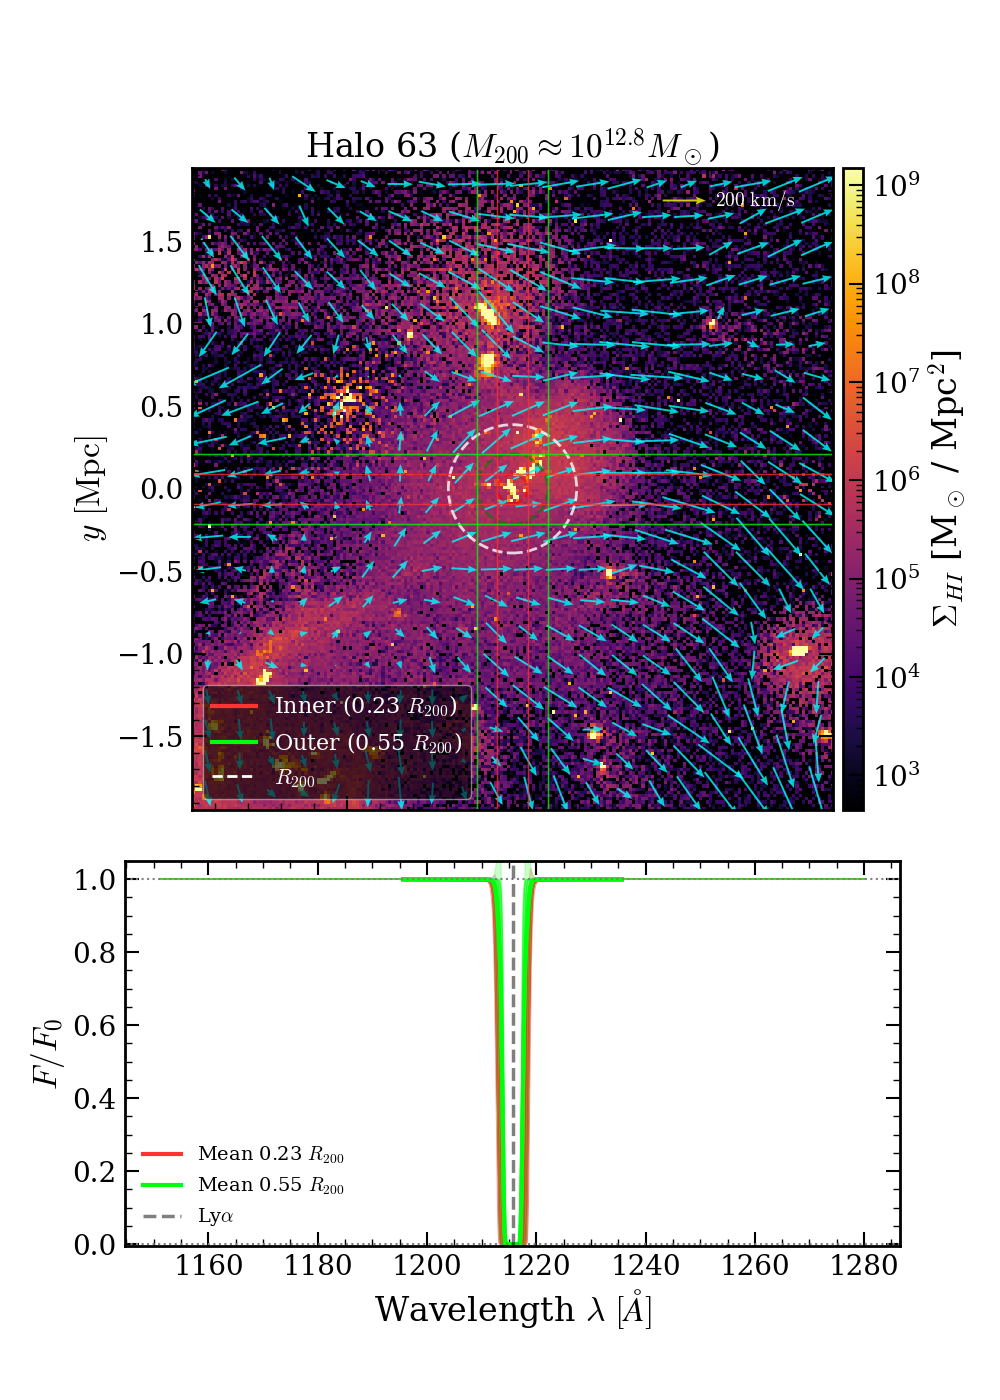

In [47]:
# --- 3. PLOTING ---
fig = plt.figure(figsize=(10, 14)) 
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 0.6], hspace=0.1)

# === AX1: GAS MAP ===
ax_map = fig.add_subplot(gs[0])
ax_map.set_facecolor('black')

# --- CORREÇÃO DE UNIDADE APENAS ---
NBINS = 200 

# 1. Calcular Histograma (Soma de Massa)
mass_grid, _, _ = np.histogram2d(
    x_gas, y_gas, 
    weights=w_gas, # M_sun
    bins=NBINS, 
    range=[[-plot_radius, plot_radius], [-plot_radius, plot_radius]]
)

# 2. Calcular Área do Pixel (Mpc^2)
pixel_width_mpc = (2 * plot_radius) / NBINS 
pixel_area_mpc2 = pixel_width_mpc**2 

# 3. Calcular Densidade Superficial (M_sun / Mpc^2)
surface_density_grid = mass_grid.T / pixel_area_mpc2 

# 4. Plotar (Mantendo suas configs visuais exatas)
# vmin e vmax baseados no SEU pedido: max * 1e-6
# Replace your current vmin/vmax calculation with:
# Use percentiles to avoid noise dominating
surface_density_nonzero = surface_density_grid[surface_density_grid > 0]

if len(surface_density_nonzero) > 0:
    v_min = np.percentile(surface_density_nonzero, 5)   # 5th percentile
    v_max = np.percentile(surface_density_nonzero, 99.5) # 99.5th percentile
else:
    v_min, v_max = 1e10, 1e24  # fallback

im = ax_map.imshow(
    surface_density_grid,
    origin='lower',
    extent=[-plot_radius, plot_radius, -plot_radius, plot_radius],
    norm=LogNorm(vmin=v_min, vmax=v_max, clip=True),  # Add clip=True
    cmap='inferno'
)


# Quiver (Voltando para config original: width 0.003, scale 3000)
q = ax_map.quiver(GX, GY, qv_vx.T, qv_vy.T, color='cyan', alpha=0.8, 
                  width=0.003, scale=3000, headwidth=4, pivot='mid') 
ax_map.quiverkey(q, 0.8, 0.95, 200, r'$200\ {\rm km/s}$', labelpos='E', coordinates='axes', labelcolor='white', color='yellow', fontproperties={'weight': 'bold'})

circle_r200 = patches.Circle((0, 0), radius=r200_mpc, fill=False, edgecolor='white', 
                             linestyle='--', linewidth=2, alpha=0.8, label=r'$R_{200}$')
circle_inner = patches.Circle((0, 0), radius=r200_mpc*TARGET_RADII[0], fill=False, edgecolor='red', 
                             linestyle='--', linewidth=2, alpha=0.6, label=r'$R_{inner}$')
circle_outer =patches.Circle((0, 0), radius=r200_mpc*TARGET_RADII[1], fill=False, edgecolor='green', 
                             linestyle='--', linewidth=2, alpha=0.6, label=r'$R_{inner}$')
 
ax_map.add_patch(circle_r200)
ax_map.add_patch(circle_inner)
ax_map.add_patch(circle_outer)

for _, row in df_plot.iterrows():
    r_imp = (row['impact_kpc'] / 1000.0) / H_HUBBLE
    if row['axis'] == 0:
        ax_map.axhline(r_imp, color=row['color'], alpha=0.3, lw=1)
        ax_map.axhline(-r_imp, color=row['color'], alpha=0.3, lw=1)
    elif row['axis'] == 1:
        ax_map.axvline(r_imp, color=row['color'], alpha=0.3, lw=1)
        ax_map.axvline(-r_imp, color=row['color'], alpha=0.3, lw=1)

ax_map.set_aspect('equal')
ax_map.set_xlim(-plot_radius, plot_radius)
ax_map.set_ylim(-plot_radius, plot_radius)
ax_map.set_ylabel(r'$y\ [{\rm Mpc}]$')
ax_map.tick_params(labelbottom=False)
ax_map.set_title(f"Halo {real_halo_id} ($M_{{200}} \\approx 10^{{{halo_mass_log:.1f}}} M_\\odot$)")

legend_elements = [
    plt.Line2D([0], [0], color=COLORS[0], lw=3, label=f'Inner ({TARGET_RADII[0]} $R_{{200}}$)'),
    plt.Line2D([0], [0], color=COLORS[1], lw=3, label=f'Outer ({TARGET_RADII[1]} $R_{{200}}$)'),
    plt.Line2D([0], [0], color='white', linestyle='--', lw=2, label=r'$R_{200}$')
]
ax_map.legend(handles=legend_elements, loc='lower left', frameon=True, 
              facecolor='black', framealpha=0.6, labelcolor='white', fontsize=16)

# AX2: ESPECTROS
ax_spec = fig.add_subplot(gs[1])
wave_grid = np.linspace(1215.67 - 20, 1215.67 + 20, 500)

for color_idx, color in enumerate(COLORS):
    group_data = df_plot[df_plot['color'] == color]
    flux_matrix = []
    for _, row in group_data.iterrows():
        w = row['wave']
        f = row['flux']
        f_interp = np.interp(wave_grid, w, f)
        flux_matrix.append(f_interp)
        ax_spec.plot(w, f, color=color, alpha=0.5, lw=0.7)
    
    flux_matrix = np.array(flux_matrix)
    mean_flux = np.mean(flux_matrix, axis=0)
    std_flux = np.nanstd(flux_matrix, axis=0)

    # Defina o nome dinamicamente (Ex: "Mean 0.23 R200")
    label_name = f"Mean {TARGET_RADII[color_idx]} $R_{{200}}$"
    
    # Adicione 'label=label_name' aqui:
    ax_spec.plot(wave_grid, mean_flux, color=color, lw=3.0, alpha=1.0, label=label_name)
    
    ax_spec.plot(wave_grid, mean_flux, color=color, lw=3.0, alpha=1.0)
    ax_spec.fill_between(wave_grid, mean_flux - std_flux, mean_flux + std_flux, color=color, alpha=0.2)

ax_spec.axhline(1.0, color='gray', linestyle=':', lw=1.5)
ax_spec.axhline(0.0, color='gray', linestyle=':', lw=1.5)
ax_spec.axvline(1215.67, color='black', linestyle='--', alpha=0.5, label=r'Ly$\alpha$')

#ax_spec.set_xlim(wave_grid[0]+4, wave_grid[-1]-4)
ax_spec.set_ylim(-0.005, 1.05)
ax_spec.set_xlabel(r'Wavelength $\lambda\ [\AA]$')
ax_spec.set_ylabel(r'$F/F_0$')

pos = ax_map.get_position()
cbar_ax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.02, pos.height])
cb = plt.colorbar(im, cax=cbar_ax)
cb.set_label(r'$\Sigma_{HI}$ [M$_\odot$ / Mpc$^2$]')
ax_spec.legend(loc='lower left', frameon=False, fontsize=14)

#plt.savefig("Paper_Ready_Figure_Fixed.pdf", bbox_inches='tight', dpi=300)
plt.show()

In [48]:
flux_matrix.shape

(12, 500)